# 04 - Feature Engineering Experiments
Do extra features improve the model? Each candidate is **added to the current feature set one at a time** and scored with
**repeated 5-fold cross-validation on the training set** (5 folds x 3 repeats = 15 scores, which reduces noise).
The test set is only used at the very end.

Same target (`log(Price)`), same split (`test_size=0.15`, `random_state=2`) as notebooks 02 and 03.

In [1]:
import re
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, RepeatedKFold, RandomizedSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.inspection import permutation_importance
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, VotingRegressor)
from xgboost import XGBRegressor

pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', None)
warnings.filterwarnings('ignore', category=UserWarning)
RS = 2

## 1. Rebuild the dataset from the raw CSV
Same steps as notebook 02 (so the current features are identical), but this time the raw `Cpu`, `Gpu`, `Memory`,
`ScreenResolution` and `Inches` are kept so new features can be extracted from them.

In [2]:
raw = pd.read_csv('laptop_data.csv').drop(columns=['Unnamed: 0'])
raw = raw[~raw['Gpu'].str.startswith('ARM')].reset_index(drop=True)      # same ARM row removed as in 02

d = pd.DataFrame(index=raw.index)
d['Company'] = raw['Company']
d['TypeName'] = raw['TypeName']
d['Ram'] = raw['Ram'].str.replace('GB', '', regex=False).astype(int)
d['Weight'] = raw['Weight'].str.replace('kg', '', regex=False).astype(float)
d['Price'] = raw['Price']
d['Touchscreen'] = raw['ScreenResolution'].str.contains('Touchscreen', case=False).astype(int)
d['Ips'] = raw['ScreenResolution'].str.contains('IPS', case=False).astype(int)
res = raw['ScreenResolution'].str.split('x', n=1, expand=True)
X_res = res[0].str.extract(r'(\d+)$')[0].astype(int)
Y_res = res[1].astype(int)
d['ppi'] = np.sqrt(X_res ** 2 + Y_res ** 2) / raw['Inches']

def cpu_brand(text):
    name = ' '.join(text.split()[:3])
    if name in ('Intel Core i7', 'Intel Core i5', 'Intel Core i3'):
        return name
    return 'Other Intel Processor' if name.split()[0] == 'Intel' else 'AMD Processor'
d['Cpu brand'] = raw['Cpu'].apply(cpu_brand)

def parse_memory(text):
    sizes = {'SSD': 0, 'HDD': 0, 'Flash Storage': 0, 'Hybrid': 0}
    for part in text.split('+'):
        size, unit, kind = re.fullmatch(r'(\d+(?:\.\d+)?)(GB|TB) (SSD|HDD|Flash Storage|Hybrid)', part.strip()).groups()
        sizes[kind] += int(float(size) * (1000 if unit == 'TB' else 1))
    return pd.Series(sizes)
mem = raw['Memory'].apply(parse_memory)
d['SSD'] = mem['SSD']
d['HDD'] = mem['HDD']
d['Gpu brand'] = raw['Gpu'].str.split().str[0]
d['os'] = raw['OpSys'].map(lambda s: 'Windows' if s in ('Windows 10', 'Windows 7', 'Windows 10 S')
                           else 'Mac' if s in ('macOS', 'Mac OS X') else 'Others/No OS/Linux')

# Sanity check: the rebuilt current features must equal laptop_clean.csv from notebook 02
clean = pd.read_csv('laptop_clean.csv')
pd.testing.assert_frame_equal(d[clean.columns], clean, check_dtype=False)
print('Rebuilt features match laptop_clean.csv exactly:', d.shape)

Rebuilt features match laptop_clean.csv exactly: (1302, 13)


## 2. Candidate new features

In [3]:
# (a) CPU clock speed in GHz, e.g. 'Intel Core i5 7200U 2.5GHz' -> 2.5
d['cpu_ghz'] = raw['Cpu'].str.extract(r'([\d.]+)GHz')[0].astype(float)

# (b) CPU type from the model-number suffix:
#     HQ/HK = high-performance (gaming/workstation), U = low-power, Y = ultra-low-power, anything else = Other
def cpu_type(text):
    if re.search(r'\d{4}H[QK]\b', text):
        return 'High-performance (H)'
    if re.search(r'\d{4}U\b', text):
        return 'Low-power (U)'
    if re.search(r'\dY\d{2}', text):
        return 'Ultra-low-power (Y)'
    return 'Other'
d['cpu_type'] = raw['Cpu'].apply(cpu_type)

# (c) Intel Core generation from the first digit of the model number (e.g. 7200U -> 7th gen, 8550U -> 8th gen)
def cpu_gen(text):
    m = re.search(r'Intel Core (?:i\d|M) (?:[mM]\d-)?(\d)(?:\d{3}|Y\d{2})', text)
    return f'Gen {m.group(1)}' if m else 'Unknown'
d['cpu_gen'] = raw['Cpu'].apply(cpu_gen)

# (d) GPU tier - finer than Gpu brand
def gpu_tier(text):
    if 'GTX' in text:                          return 'Nvidia GTX'
    if 'Quadro' in text:                       return 'Nvidia Quadro'
    if text.startswith('Nvidia'):              return 'Nvidia other (MX/GT/9xxMX)'
    if 'FirePro' in text or 'Radeon Pro' in text: return 'AMD Pro/FirePro'
    if text.startswith('AMD'):                 return 'AMD other'
    if 'Iris' in text:                         return 'Intel Iris'
    return 'Intel HD/UHD'
d['gpu_tier'] = raw['Gpu'].apply(gpu_tier)

# (e) Screen size & resolution that were dropped in favour of ppi
d['Inches'] = raw['Inches']
d['X_res'] = X_res
d['Y_res'] = Y_res

# (f) Storage types that were dropped
d['Flash Storage'] = mem['Flash Storage']
d['Hybrid'] = mem['Hybrid']

for col in ['cpu_type', 'cpu_gen', 'gpu_tier']:
    print(d[col].value_counts(), '\n')
print(d['cpu_ghz'].describe().round(2))

cpu_type
Low-power (U)           802
High-performance (H)    266
Other                   210
Ultra-low-power (Y)      24
Name: count, dtype: int64 

cpu_gen
Gen 7      615
Gen 6      322
Unknown    218
Gen 8      147
Name: count, dtype: int64 

gpu_tier
Intel HD/UHD                  708
Nvidia GTX                    239
AMD other                     172
Nvidia other (MX/GT/9xxMX)    130
Nvidia Quadro                  31
Intel Iris                     14
AMD Pro/FirePro                 8
Name: count, dtype: int64 

count    1302.00
mean        2.30
std         0.51
min         0.90
25%         2.00
50%         2.50
75%         2.70
max         3.60
Name: cpu_ghz, dtype: float64


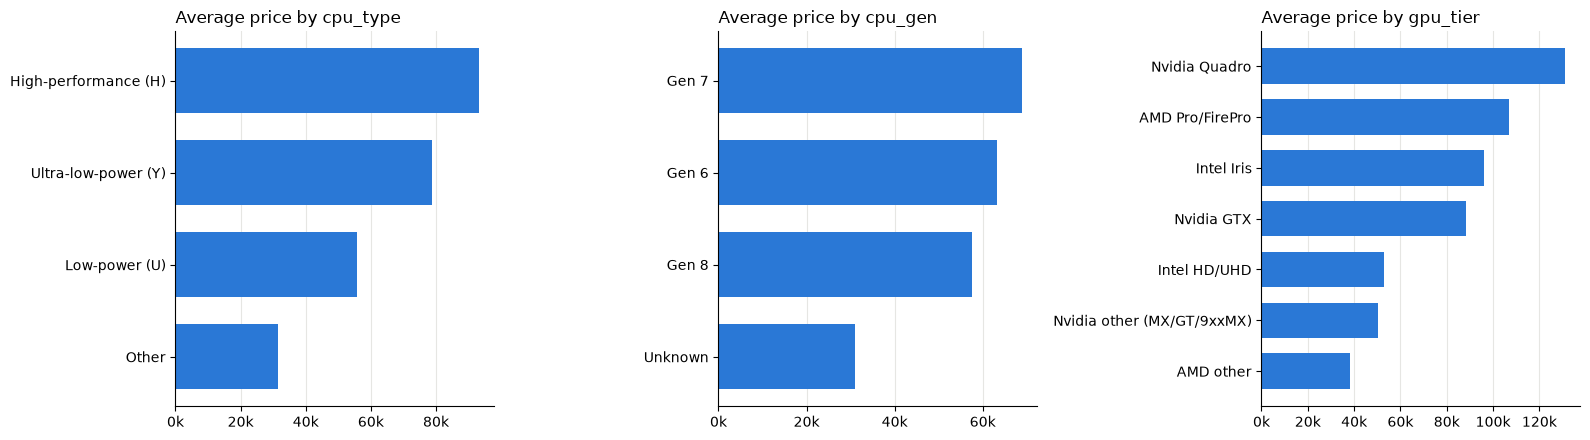

Correlation of cpu_ghz with Price: 0.43


In [4]:
# Quick look: do the new categorical features separate prices?
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ['cpu_type', 'cpu_gen', 'gpu_tier']):
    s = d.groupby(col)['Price'].mean().sort_values()
    ax.barh(s.index, s.values, color='#2a78d6', height=0.7)
    ax.set_title(f'Average price by {col}', loc='left')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1000:.0f}k'))
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='x', color='#e6e6e3', linewidth=0.8)
    ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('new_features_price.png', dpi=120, bbox_inches='tight')
plt.show()
print('Correlation of cpu_ghz with Price:', round(d['cpu_ghz'].corr(d['Price']), 3))

## 3. Same split as before

In [5]:
y = np.log(d['Price'])
idx_train, idx_test = train_test_split(d.index, test_size=0.15, random_state=RS)

# Confirm this is exactly the split used in notebooks 02/03
_, X_test_03, _, _ = train_test_split(clean.drop(columns=['Price']), np.log(clean['Price']), test_size=0.15, random_state=RS)
assert list(idx_test) == list(X_test_03.index)
print('Train:', len(idx_train), ' Test:', len(idx_test), '(identical split to notebook 03)')

# (g) Rare companies -> 'Other'. The list of rare brands is decided from the TRAINING rows only (no test leakage)
company_counts_train = d.loc[idx_train, 'Company'].value_counts()
rare_companies = company_counts_train[company_counts_train < 10].index.tolist()
d['Company_grouped'] = d['Company'].where(~d['Company'].isin(rare_companies), 'Other')
print('Grouped into Other:', rare_companies)

Train: 1106  Test: 196 (identical split to notebook 03)
Grouped into Other: ['Razer', 'Mediacom', 'Samsung', 'Microsoft', 'Vero', 'LG', 'Google', 'Chuwi', 'Fujitsu', 'Xiaomi', 'Huawei']


## 4. Experiment: add one feature group at a time
Two strong models with the **best settings found in notebook 03**, so only the features change:
Gradient Boosting and XGBoost. Score = mean R² over 15 CV folds on the training set.

In [6]:
BASE_CAT = ['Company', 'TypeName', 'Cpu brand', 'Gpu brand', 'os']
BASE_NUM = ['Ram', 'Weight', 'Touchscreen', 'Ips', 'ppi', 'SSD', 'HDD']

def make_models():
    return {
        'Gradient Boosting': GradientBoostingRegressor(random_state=RS, subsample=0.6, n_estimators=700, min_samples_leaf=5,
                                                       max_features=0.3, max_depth=5, learning_rate=0.05),
        'XGBoost': XGBRegressor(random_state=RS, n_jobs=1, tree_method='hist', subsample=1.0, reg_lambda=5, n_estimators=500,
                                min_child_weight=3, max_depth=5, learning_rate=0.1, colsample_bytree=0.4),
    }

def make_pipe(model, cat_cols, num_cols):
    pre = ColumnTransformer([
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols),
        ('num', 'passthrough', num_cols),
    ])
    return Pipeline([('preprocess', pre), ('model', model)])

rcv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RS)

def cv_score(cat_cols, num_cols):
    X_tr = d.loc[idx_train, cat_cols + num_cols]
    y_tr = y.loc[idx_train]
    out = {}
    for name, model in make_models().items():
        out[name] = cross_val_score(make_pipe(model, cat_cols, num_cols), X_tr, y_tr, cv=rcv, scoring='r2', n_jobs=-1).mean()
    return out

# Each experiment = (extra categorical cols, extra numeric cols, categorical cols to REMOVE)
experiments = {
    'Baseline (current 12 features)':      ([], [], []),
    '+ cpu_ghz':                           ([], ['cpu_ghz'], []),
    '+ cpu_type':                          (['cpu_type'], [], []),
    '+ cpu_gen':                           (['cpu_gen'], [], []),
    '+ gpu_tier':                          (['gpu_tier'], [], []),
    'gpu_tier instead of Gpu brand':       (['gpu_tier'], [], ['Gpu brand']),
    'Company_grouped instead of Company':  (['Company_grouped'], [], ['Company']),
    '+ Inches, X_res, Y_res':              ([], ['Inches', 'X_res', 'Y_res'], []),
    '+ Flash Storage, Hybrid':             ([], ['Flash Storage', 'Hybrid'], []),
}

rows = []
for name, (add_cat, add_num, remove_cat) in experiments.items():
    start = time.time()
    cat_cols = [c for c in BASE_CAT if c not in remove_cat] + add_cat
    num_cols = BASE_NUM + add_num
    scores = cv_score(cat_cols, num_cols)
    rows.append({'Experiment': name, **scores})
    print(f"{name:<38} GB = {scores['Gradient Boosting']:.4f}  XGB = {scores['XGBoost']:.4f}  ({time.time() - start:.0f}s)")

exp_df = pd.DataFrame(rows).set_index('Experiment')
base = exp_df.iloc[0]
exp_df['GB change'] = exp_df['Gradient Boosting'] - base['Gradient Boosting']
exp_df['XGB change'] = exp_df['XGBoost'] - base['XGBoost']
exp_df['Avg change'] = exp_df[['GB change', 'XGB change']].mean(axis=1)
exp_df.round(4)

Baseline (current 12 features)         GB = 0.8871  XGB = 0.8938  (4s)


+ cpu_ghz                              GB = 0.8960  XGB = 0.9006  (1s)


+ cpu_type                             GB = 0.8932  XGB = 0.8990  (2s)


+ cpu_gen                              GB = 0.8945  XGB = 0.8986  (2s)


+ gpu_tier                             GB = 0.8948  XGB = 0.8981  (2s)


gpu_tier instead of Gpu brand          GB = 0.8933  XGB = 0.8979  (2s)


Company_grouped instead of Company     GB = 0.8903  XGB = 0.8971  (1s)


+ Inches, X_res, Y_res                 GB = 0.8889  XGB = 0.8971  (1s)


+ Flash Storage, Hybrid                GB = 0.8867  XGB = 0.8929  (1s)


,Gradient Boosting,XGBoost,GB change,XGB change,Avg change
Experiment,,,,,
Baseline (current 12 features),0.8871,0.8938,0.0000,0.0000,0.0000
+ cpu_ghz,0.8960,0.9006,0.0089,0.0069,0.0079
+ cpu_type,0.8932,0.8990,0.0060,0.0053,0.0057
+ cpu_gen,0.8945,0.8986,0.0074,0.0049,0.0062
+ gpu_tier,0.8948,0.8981,0.0076,0.0044,0.0060
gpu_tier instead of Gpu brand,0.8933,0.8979,0.0062,0.0041,0.0052
Company_grouped instead of Company,0.8903,0.8971,0.0032,0.0033,0.0033
"+ Inches, X_res, Y_res",0.8889,0.8971,0.0018,0.0033,0.0025
"+ Flash Storage, Hybrid",0.8867,0.8929,-0.0004,-0.0009,-0.0007


## 5. Combine the features that helped
A feature group is kept if it improved the **average** CV R² of the two models.

In [7]:
helpful = [name for name in exp_df.index[1:] if exp_df.loc[name, 'Avg change'] > 0]
print('Helpful experiments:', helpful)

final_cat, final_num = list(BASE_CAT), list(BASE_NUM)
for name in helpful:
    add_cat, add_num, remove_cat = experiments[name]
    final_cat = [c for c in final_cat if c not in remove_cat] + [c for c in add_cat if c not in final_cat]
    final_num = final_num + [c for c in add_num if c not in final_num]

print('Final categorical:', final_cat)
print('Final numeric:    ', final_num)

combined = cv_score(final_cat, final_num)
print(f"\nCombined feature set  GB = {combined['Gradient Boosting']:.4f} ({combined['Gradient Boosting'] - base['Gradient Boosting']:+.4f})"
      f"   XGB = {combined['XGBoost']:.4f} ({combined['XGBoost'] - base['XGBoost']:+.4f})")

Helpful experiments: ['+ cpu_ghz', '+ cpu_type', '+ cpu_gen', '+ gpu_tier', 'gpu_tier instead of Gpu brand', 'Company_grouped instead of Company', '+ Inches, X_res, Y_res']
Final categorical: ['TypeName', 'Cpu brand', 'os', 'cpu_type', 'cpu_gen', 'gpu_tier', 'Company_grouped']
Final numeric:     ['Ram', 'Weight', 'Touchscreen', 'Ips', 'ppi', 'SSD', 'HDD', 'cpu_ghz', 'Inches', 'X_res', 'Y_res']



Combined feature set  GB = 0.9063 (+0.0192)   XGB = 0.9105 (+0.0167)


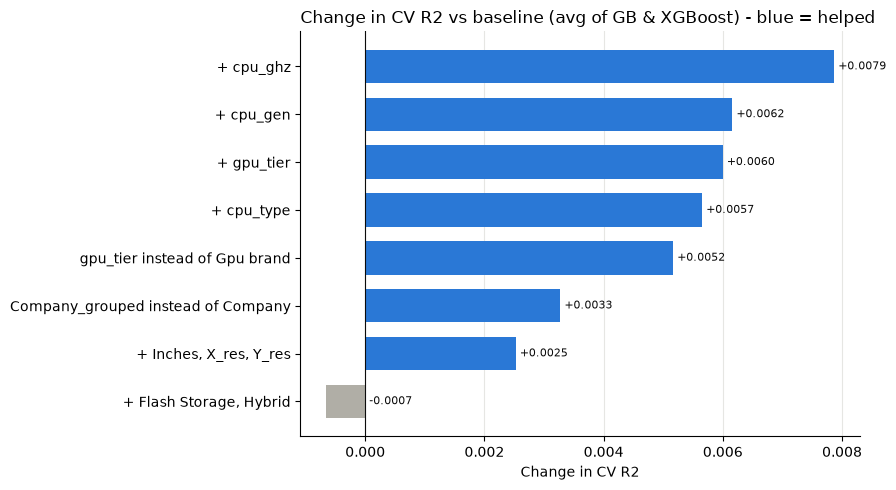

In [8]:
# Chart: change in CV R2 per experiment
plot_df = exp_df.iloc[1:].sort_values('Avg change')
fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#2a78d6' if v > 0 else '#b0aea6' for v in plot_df['Avg change']]
ax.barh(plot_df.index, plot_df['Avg change'], color=colors, height=0.7)
ax.axvline(0, color='#0b0b0b', linewidth=0.8)
for y_pos, v in enumerate(plot_df['Avg change']):
    ax.text(max(v, 0), y_pos, f' {v:+.4f}', va='center', ha='left', fontsize=8, color='#0b0b0b')
ax.set_title('Change in CV R2 vs baseline (avg of GB & XGBoost) - blue = helped', loc='left')
ax.set_xlabel('Change in CV R2')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('feature_experiments.png', dpi=120, bbox_inches='tight')
plt.show()

## 6. Re-tune the top models on the final feature set
Same search spaces as notebook 03 (RandomizedSearchCV, 40 combinations, 5-fold CV on training data), then a Voting ensemble of the four.

In [9]:
X_train = d.loc[idx_train, final_cat + final_num]
X_test = d.loc[idx_test, final_cat + final_num]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]
cv = KFold(n_splits=5, shuffle=True, random_state=RS)

search_spaces = {
    'Gradient Boosting': (GradientBoostingRegressor(random_state=RS), {
        'model__n_estimators': [200, 400, 700, 1000], 'model__learning_rate': [0.02, 0.05, 0.1],
        'model__max_depth': [2, 3, 4, 5, 6], 'model__subsample': [0.6, 0.8, 1.0],
        'model__max_features': [0.3, 0.5, 0.75, None], 'model__min_samples_leaf': [1, 3, 5]}),
    'Hist Gradient Boosting': (HistGradientBoostingRegressor(random_state=RS), {
        'model__learning_rate': [0.02, 0.05, 0.1], 'model__max_iter': [200, 400, 700],
        'model__max_leaf_nodes': [8, 15, 31, 63], 'model__min_samples_leaf': [5, 10, 20],
        'model__l2_regularization': [0.0, 0.1, 1.0]}),
    'XGBoost': (XGBRegressor(random_state=RS, n_jobs=1, tree_method='hist'), {
        'model__n_estimators': [300, 500, 800, 1200], 'model__learning_rate': [0.02, 0.05, 0.1],
        'model__max_depth': [3, 4, 5, 6, 8], 'model__subsample': [0.6, 0.8, 1.0],
        'model__colsample_bytree': [0.4, 0.6, 0.8, 1.0], 'model__min_child_weight': [1, 3, 5],
        'model__reg_lambda': [0.5, 1, 5]}),
    'Random Forest': (RandomForestRegressor(random_state=RS, n_jobs=1), {
        'model__n_estimators': [200, 400, 600], 'model__max_depth': [None, 10, 15, 20],
        'model__max_features': [0.3, 0.5, 0.75, 1.0], 'model__min_samples_leaf': [1, 2, 4],
        'model__max_samples': [None, 0.5, 0.75]}),
}

def scores(name, pipe, cv_r2, params):
    p_tr, p_te = pipe.predict(X_train), pipe.predict(X_test)
    return {'Model': name, 'CV R2': cv_r2, 'Train R2': r2_score(y_train, p_tr), 'Test R2': r2_score(y_test, p_te),
            'Test MAE (log)': mean_absolute_error(y_test, p_te),
            'Test MAE (price)': mean_absolute_error(np.exp(y_test), np.exp(p_te)), 'Best params': params}

final_results, final_pipes = [], {}
for name, (model, grid) in search_spaces.items():
    start = time.time()
    search = RandomizedSearchCV(make_pipe(model, final_cat, final_num), grid, n_iter=40, cv=cv,
                                scoring='r2', n_jobs=-1, random_state=RS)
    search.fit(X_train, y_train)
    final_pipes[name] = search.best_estimator_
    params = {k.replace('model__', ''): v for k, v in search.best_params_.items()}
    final_results.append(scores(name, search.best_estimator_, search.best_score_, params))
    print(f"{name:<24} CV R2 = {search.best_score_:.4f} | Test R2 = {final_results[-1]['Test R2']:.4f} | {time.time() - start:.0f}s")

voting = VotingRegressor([(n, final_pipes[n]) for n in search_spaces], n_jobs=-1)
voting_cv = cross_val_score(voting, X_train, y_train, cv=cv, scoring='r2', n_jobs=-1).mean()
voting.fit(X_train, y_train)
final_pipes['Voting (top 4)'] = voting
final_results.append(scores('Voting (top 4)', voting, voting_cv, {'members': list(search_spaces)}))
print(f"{'Voting (top 4)':<24} CV R2 = {voting_cv:.4f} | Test R2 = {final_results[-1]['Test R2']:.4f}")

Gradient Boosting        CV R2 = 0.9113 | Test R2 = 0.9225 | 20s


Hist Gradient Boosting   CV R2 = 0.9065 | Test R2 = 0.9173 | 29s


XGBoost                  CV R2 = 0.9130 | Test R2 = 0.9202 | 8s


Random Forest            CV R2 = 0.8930 | Test R2 = 0.9136 | 25s


Voting (top 4)           CV R2 = 0.9129 | Test R2 = 0.9246


## 7. Before vs after feature engineering

In [10]:
# Scores from notebook 03 (original 12 features), same split and same search settings
before = pd.DataFrame([
    {'Model': 'Gradient Boosting',      'CV R2': 0.8912, 'Test R2': 0.9057, 'Test MAE (price)': 8398},
    {'Model': 'Hist Gradient Boosting', 'CV R2': 0.8878, 'Test R2': 0.9082, 'Test MAE (price)': 8198},
    {'Model': 'XGBoost',                'CV R2': 0.8972, 'Test R2': 0.8958, 'Test MAE (price)': 8306},
    {'Model': 'Random Forest',          'CV R2': 0.8798, 'Test R2': 0.8987, 'Test MAE (price)': 8633},
    {'Model': 'Voting (top 4)',         'CV R2': 0.8969, 'Test R2': 0.9098, 'Test MAE (price)': 7934},
]).set_index('Model')

after = pd.DataFrame(final_results).set_index('Model')
compare = pd.DataFrame({
    'CV R2 before': before['CV R2'], 'CV R2 after': after['CV R2'],
    'Test R2 before': before['Test R2'], 'Test R2 after': after['Test R2'],
    'Test MAE before': before['Test MAE (price)'], 'Test MAE after': after['Test MAE (price)'],
})
compare['CV R2 change'] = compare['CV R2 after'] - compare['CV R2 before']
compare.round(4)

,CV R2 before,CV R2 after,Test R2 before,Test R2 after,Test MAE before,Test MAE after,CV R2 change
Model,,,,,,,
Gradient Boosting,0.8912,0.9113,0.9057,0.9225,8398,7609.4996,0.0201
Hist Gradient Boosting,0.8878,0.9065,0.9082,0.9173,8198,7806.7556,0.0187
XGBoost,0.8972,0.9130,0.8958,0.9202,8306,7536.5679,0.0158
Random Forest,0.8798,0.8930,0.8987,0.9136,8633,8112.7276,0.0132
Voting (top 4),0.8969,0.9129,0.9098,0.9246,7934,7379.5663,0.0160


In [11]:
for _, row in after.iterrows():
    print(f"{row.name}: Train R2 = {row['Train R2']:.4f}, Test MAE (log) = {row['Test MAE (log)']:.4f}")
    print('   ', row['Best params'])

Gradient Boosting: Train R2 = 0.9748, Test MAE (log) = 0.1327
    {'subsample': 0.8, 'n_estimators': 1000, 'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 4, 'learning_rate': 0.05}
Hist Gradient Boosting: Train R2 = 0.9686, Test MAE (log) = 0.1351
    {'min_samples_leaf': 10, 'max_leaf_nodes': 15, 'max_iter': 400, 'learning_rate': 0.05, 'l2_regularization': 1.0}
XGBoost: Train R2 = 0.9812, Test MAE (log) = 0.1308
    {'subsample': 1.0, 'reg_lambda': 5, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.4}
Random Forest: Train R2 = 0.9758, Test MAE (log) = 0.1411
    {'n_estimators': 600, 'min_samples_leaf': 1, 'max_samples': 0.75, 'max_features': 0.3, 'max_depth': None}
Voting (top 4): Train R2 = 0.9778, Test MAE (log) = 0.1283
    {'members': ['Gradient Boosting', 'Hist Gradient Boosting', 'XGBoost', 'Random Forest']}


## 8. Which features does the final model rely on?
Permutation importance: shuffle one column at a time in the test set and measure how much R² drops. A bigger drop = more important.

Best model by CV R2: XGBoost


Ram                0.1085
SSD                0.0612
Weight             0.0611
cpu_ghz            0.0578
Cpu brand          0.0463
cpu_gen            0.0318
Company_grouped    0.0307
os                 0.0214
TypeName           0.0198
gpu_tier           0.0173
cpu_type           0.0139
ppi                0.0123
Inches             0.0105
X_res              0.0104
HDD                0.0088
Ips                0.0066
Y_res              0.0054
Touchscreen        0.0053
dtype: float64


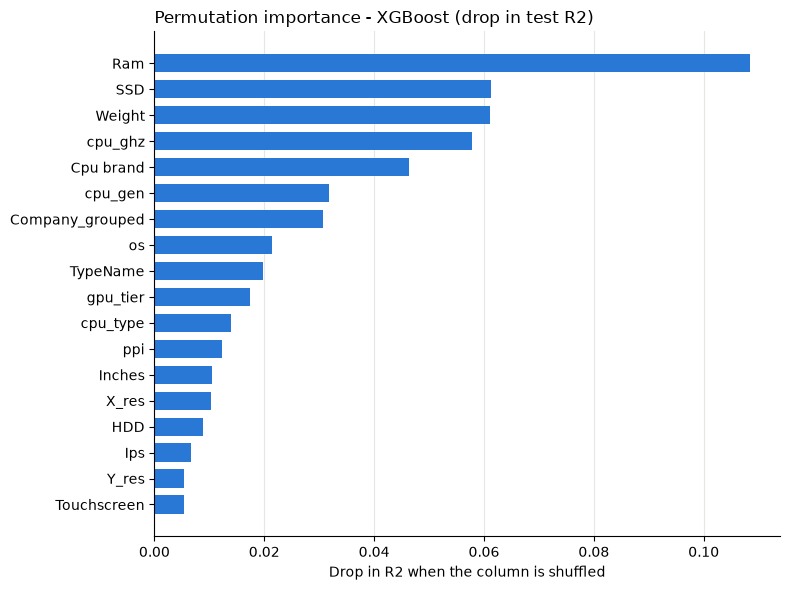

In [12]:
best_name = after['CV R2'].idxmax()
best_pipe = final_pipes[best_name]
print('Best model by CV R2:', best_name)

perm = permutation_importance(best_pipe, X_test, y_test, n_repeats=10, random_state=RS, scoring='r2', n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
print(imp.sort_values(ascending=False).round(4))

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp.index, imp.values, color='#2a78d6', height=0.7)
ax.set_title(f'Permutation importance - {best_name} (drop in test R2)', loc='left')
ax.set_xlabel('Drop in R2 when the column is shuffled')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', color='#e6e6e3', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('feature_importance.png', dpi=120, bbox_inches='tight')
plt.show()